## Гидрометеорологический анализ факторов весеннего половодья реки Урал (г. Оренбург)


## Введение
Река Урал имеет восточноевропейский тип водного режима с преобладанием снегового питания,
в связи с чем до 80% годового стока приходится на период весеннего половодья.
В некоторые годы сильное поднятие уровня воды весной приводило к большим жертвам и к серьезному материальному ущербу.

Ключевыми предвестниками экстремальных паводков в среднем течении Урала выступают два фактора:
1) Запас воды в снежном покрове к началу таяния (определяется суммой осадков за холодный период года (ноябрь-март)).
2) Интенсивность весеннего снеготаяния (зависит от средней температуры воздуха в апреле).
## Источники данных:
В работе используются данные с метеостанции Оренбург (35121), полученные с портала "Погода и климат" за период наблюдений с 1952 по 2025 год:
1) 'data/orenburg_temp.csv' - среднемесячные и среднегодовые температуры воздуха.
2) 'data/orenburg_precip.csv' - месячные и годовые суммы выпавших осадков.

Файлы являются таблицами с разделителями ";", ",". Для их очистки для дальнейшего анализа был создан собственный модуль.

Такой же анализ можно провести в этом проекте и по другим станциям, для этого нужно зайти на сайт "Погода и климат",  скопировать нужные данные по станции с 1952 года (так как в более ранние периоды данные обычно с пробелами), сохранить в папку data в формате "csv(разделитель-запятая)" и в шаге 1 поменять название таблицы на то, которое вы указали.
## Используемые модули и инструменты:
1) **numpy**  - библиотека для расчетов над многомерными массивами, вычислением норм и фильтрации данных.
2) **matplotlib.pyplot** - модуль для визуализации.
3) **project_tools** - вспомогательный модуль(project_tools.py), написанный для данного проекта. Содержит функции:
* load_data_csv() - чтение и очистка табличных данных, замена разделителей, удаление пустых ячеек, конвертация в матрицу numpy
* calculate_cold_season_precip() - расчет суммарных осадков холодного сезона
* filter_flood_risk_years() - создание булевой маски для отбора лет превышением и нормы зимних осадков и нормы температуры апреля



In [1]:
# Импорт инструментов
import numpy as np
import matplotlib.pyplot as plt
import project_tools as pt

## Шаг 1

загрузка и очистка данных 

In [2]:
temp_data = pt.load_data_csv('data/orenburg_temp.csv') #Таблица температур
precip_data = pt.load_data_csv('data/orenburg_precip.csv') # Таблица осадков
years = temp_data[:, 0].astype(int) #Извлечение столбца с годами наблюдений
temp_mar = temp_data[:, 3] # Извлечение столбца с температурами марта
temp_apr = temp_data[:, 4] # Извлечение столбца с температурами апреля
temp_year = temp_data[:, 13] # Извлечение столбца со среднегодовыми значениями

## Шаг 2

Расчет осадков в холодный период (ноябрь-март)

In [3]:
cold_precip = pt.calculate_cold_season_precip(precip_data) # Вычисление суммы осадков холодного периода

## Шаг 3

Выделение годов с высоким паводковым риском при помощи булевой маски

In [4]:
risk_mask = pt.filter_flood_risk_years(years, cold_precip, temp_apr) # Формирование булевой маски
print(years[risk_mask])

[1962 1966 1970 1976 1982 1983 1990 1997 1999 2000 2001 2008 2010 2013
 2016 2024]


## Шаг 4
Построение двухпанельной диаграммы с общей временной осью за 1952-2025 г:
1) Верхняя панель - динамика накопления осадков в холодный период (ноябрь-март) и линия многолетней климатической нормы. С помощью индексации по булевой маске обычные годы окрашены в синий цвет, а годы с сочетанием двух факторов паводкового риска - в красный.
2) Нижняя панель - отклонения температуры апреля относительно нормы. Красным выделены температурные аномалии, совпавшие с многоснежными зимами.



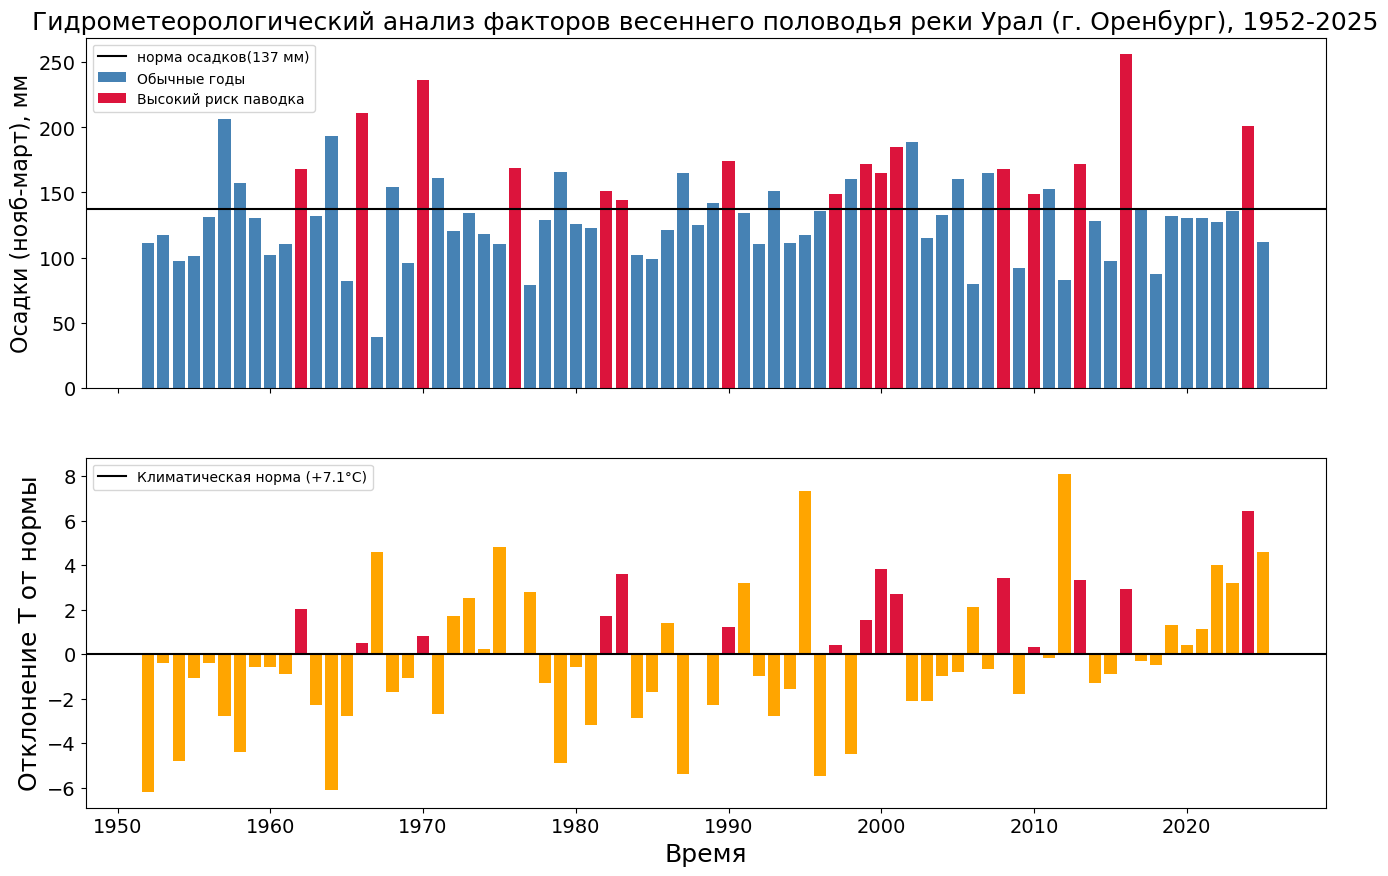

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

ax1.bar(years[~risk_mask], cold_precip[~risk_mask], color = 'steelblue', label = 'Обычные годы')
ax1.bar(years[risk_mask], cold_precip[risk_mask], color = 'crimson', label = 'Высокий риск паводка')
ax1.axhline(np.mean(cold_precip), color = 'black', label = f'норма осадков({np.mean(cold_precip):.0f} мм)')
ax1.set_title('Гидрометеорологический анализ факторов весеннего половодья реки Урал (г. Оренбург), 1952-2025', fontsize=18)
ax1.set_ylabel('Осадки (нояб-март), мм', fontsize=16)
ax1.legend(fontsize=10, loc='upper left')
ax1.tick_params(labelsize=14)

temp_anomaly = temp_apr - np.mean(temp_apr)
colors_temp = np.where(risk_mask&(temp_anomaly>0), 'crimson', 'orange')
ax2.bar (years, temp_anomaly, color=colors_temp)
ax2.axhline(0, color='black', linestyle='-', label=f'Климатическая норма (+{np.mean(temp_apr):.1f}°C)')
ax2.set_xlabel('Время', fontsize=18)
ax2.set_ylabel('Отклонение Т от нормы', fontsize=18)
ax2.legend(fontsize=10, loc='upper left')
ax2.tick_params(labelsize=14)
plt.savefig('figures/orenburg_flood_analysis.png', bbox_inches='tight', dpi=300)
plt.show()

## Выводы

На основе проведенного анализа метеорологических рядов станции Оренбург за 1952-2025г. получены следующие результаты:
1) Рассчитана средняя сумма осадков холодного периода (137мм), средняя температура апреля (7.1°C) за 74 года.
2) Построены графики с зимним осадконакоплением и отклонением температуры апреля, средней нормой осадков и температуры.
3) С помощью булевых масок выделено 16 лет, в которых высокое снегонакопление сочеталось с аномально теплой весной, выделенные годы отмечены на графике и совпадают с реальными наблюдениями (например, половодье 2024 года).
